In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
df = pd.DataFrame(
    {
        "Date": pd.date_range("2023-01-01", periods=16, freq="D"),
        "Product": ["Product A", "Product B", "Product A", "Product C"] * 4,
        "Sales": [
            200,
            150,
            220,
            300,
            180,
            250,
            210,
            340,
            190,
            260,
            230,
            320,
            240,
            280,
            310,
            330,
        ],
        "Quantity": [4, 3, 5, 6, 4, 6, 5, 8, 4, 6, 5, 7, 6, 7, 8, 7],
        "Region": ["North", "South", "North", "East", "West", "North", "South", "East"]
        * 2,
    }
)
print(df.head())
print(df.isnull().sum())
df["Sales"] = df["Sales"].fillna(df["Sales"].mean())
print(df.describe())


        Date    Product  Sales  Quantity Region
0 2023-01-01  Product A    200         4  North
1 2023-01-02  Product B    150         3  South
2 2023-01-03  Product A    220         5  North
3 2023-01-04  Product C    300         6   East
4 2023-01-05  Product A    180         4   West
Date        0
Product     0
Sales       0
Quantity    0
Region      0
dtype: int64
                      Date       Sales   Quantity
count                   16   16.000000  16.000000
mean   2023-01-08 12:00:00  250.625000   5.687500
min    2023-01-01 00:00:00  150.000000   3.000000
25%    2023-01-04 18:00:00  207.500000   4.750000
50%    2023-01-08 12:00:00  245.000000   6.000000
75%    2023-01-12 06:00:00  302.500000   7.000000
max    2023-01-16 00:00:00  340.000000   8.000000
std                    NaN   58.019393   1.493039


     Product  Sales  Quantity
0  Product A   1780        41
1  Product B    940        22
2  Product C   1290        28


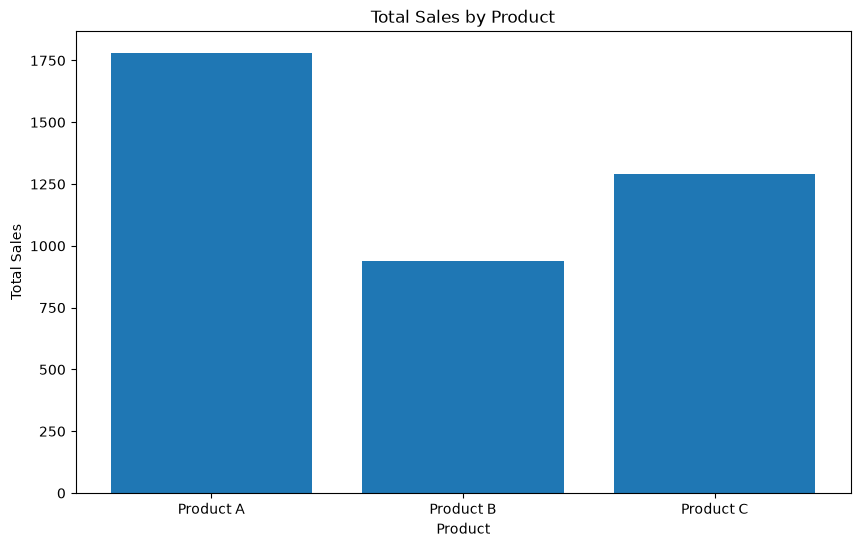

In [3]:
product_summary = (
    df.groupby("Product").agg({"Sales": "sum", "Quantity": "sum"}).reset_index()
)
print(product_summary)
plt.figure(figsize=(10, 6))
plt.bar(product_summary["Product"], product_summary["Sales"])
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.title("Total Sales by Product")
plt.show()


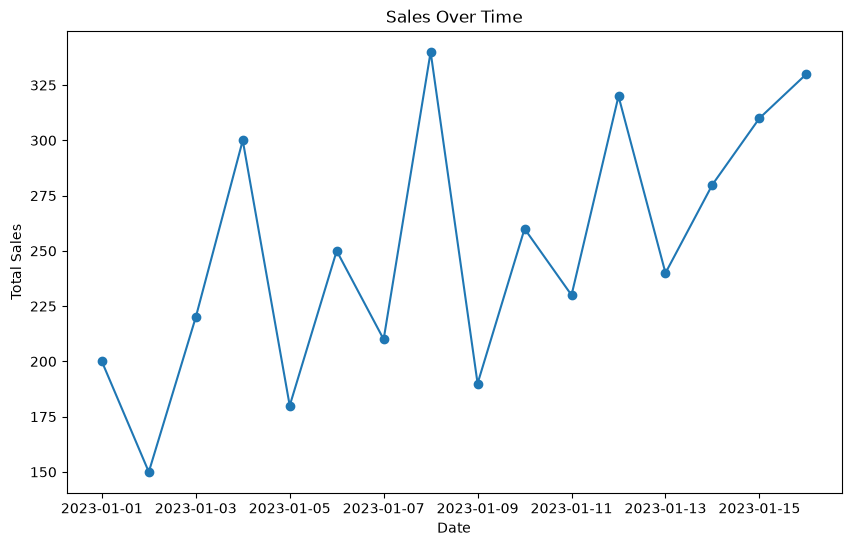

In [4]:
sales_over_time = df.groupby("Date").agg({"Sales": "sum"}).reset_index()
plt.figure(figsize=(10, 6))
plt.plot(sales_over_time["Date"], sales_over_time["Sales"], marker="o")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.title("Sales Over Time")
plt.show()


Product  Product A  Product B  Product C
Region                                  
East             0          0       1290
North          840        530          0
South          520        410          0
West           420          0          0
             Sales  Quantity
Sales     1.000000  0.949011
Quantity  0.949011  1.000000


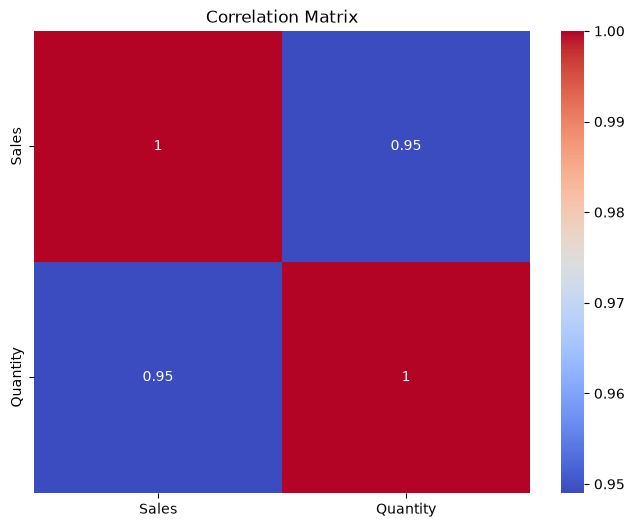

In [5]:
pivot_table = df.pivot_table(
    values="Sales", index="Region", columns="Product", aggfunc="sum", fill_value=0
)
print(pivot_table)
correlation_matrix = df[["Sales", "Quantity"]].corr()
print(correlation_matrix)
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()
